# Notebook 04 — Stage 1: neutral assignment and GLS demand estimation

First outer-loop pass of the architecture in Figure 1 (§4.1). It:

1. Loads the LTS/grade network from Notebook 02 as the single routable graph `G` (the largest strongly
   connected component, `G_scc`; §4.3) and derives the **low-stress link set** `E_low = {e : LTS_e ≤ τ_low}`,
   τ_low = 1 (§4.6). Both rider classes route on `G`: the low-stress class routes on it under the
   stress-averse cost (its routing network `N_low`) and the stress-tolerant class under the grade-adjusted
   time cost (`N_high`). `N_low` and `N_high` share `G`'s topology and differ only in edge cost — the
   λ_stress penalty on links outside `E_low` — and are applied in Notebook 05. `E_low` here is a link
   **set**, not a separately-routed subnetwork.
2. **Stage 1, first outer iteration (§4.1, §4.5).** With no converged share vector yet, *all* demand is
   routed on `G` by **all-or-nothing** (k = 1), giving the neutral incidence matrix `A_neutral`.
   Bell's (1991) **constrained GLS** then turns the seed `n` into the calibrated demand `t`.
3. Saves `t` and `A_neutral_links` (read by Notebooks 05 and 06) plus diagnostics.

**Alignment with Chapter 4**

- **Single routable graph** `G`; the two class routings `N_low` and `N_high` are penalty-based on
  `E_low = {LTS ≤ 1}` (§4.3, §4.6) and applied in Notebook 05, where they differ materially
  (|A_low − A_high| ≈ 120 %), so π_low is identified.
- **Cordon (§4.2.4):** the fixed, dissolved study-area polygon `study_area_cordon.gpkg`, applied across stages.
- **Through trips** are kept when their least-cost path on `G` crosses the cordon and their length
  ≤ the 99.5th percentile of snapped external trips (§4.2.1).
- **Counts (§4.2.3):** `v_obs` is bidirectional, ½·Σ over both 2025 rounds of mean(06,07,08); stations
  snap to `G_scc` within `COUNT_SNAP_TOL_M` (45 m), giving the **77** monitored stations used for calibration.

> **Code vs thesis naming.** The code below keeps internal variable names: `N_full` is the thesis's `G`,
> and `subnets["low"]` / `N_low` in the Section B reconstruction is the **LTS≤1 edge-subgraph** (the link
> set `E_low`, used only for the context figure) — *not* the thesis's cost-weighted `N_low`, which is `G`
> under the low-stress cost and lives in Notebook 05.


# A — Setup


## A.1 Environment and directories

Imports, project folders, the two coordinate systems (metric EPSG:28356 for distances, lat/lon for raw
points), and a figure-saving helper.


In [6]:
import os
from pathlib import Path
from datetime import datetime
from collections import defaultdict, Counter

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import networkx as nx
import osmnx as ox
from scipy import sparse
from scipy.optimize import lsq_linear
from scipy.stats import pearsonr
from shapely.geometry import Point, LineString
import thesis_common as tc

# Establish root directory and subdirectories for data, figures, and reports
PROJECT_ROOT   = Path(os.getcwd())
DATA_RAW       = PROJECT_ROOT / "data" / "raw"
DATA_PROCESSED = PROJECT_ROOT / "data" / "processed"
FIGURES        = PROJECT_ROOT / "figures"
REPORTS        = PROJECT_ROOT / "reports"
for p in (DATA_PROCESSED, FIGURES, REPORTS):
    p.mkdir(parents=True, exist_ok=True)

# Generate a unique timestamp stamp for file tracking and set coordinate reference systems
RUN_STAMP     = datetime.now().strftime("%Y%m%d_%H%M")
PROJECTED_CRS = "EPSG:28356"    # GDA94 / MGA Zone 56 — metric projection for spatial calculations
CENTROID_CRS  = "EPSG:4326"     # WGS84 lat/lon coordinate system for raw points
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 10})

# Helper function to save generated matplotlib figures with consistent formatting
def save_fig(fig, name):
    out = FIGURES / f"04_{name}_{RUN_STAMP}.png"
    fig.savefig(out, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    print(f"  saved {out.name}")

print("Run stamp:", RUN_STAMP)

Run stamp: 20261104_2129


## A.2 Configuration and parameters

Input paths (Notebook 02/03 outputs and the ABS/count raw files) and the model hyper-parameters pulled
from `thesis_common`: the low-stress threshold, the count-snap tolerance, the GLS prior and count window.


In [7]:
# ── CONFIG: input paths and model parameters (edit paths to match your machine, then run top to bottom) ──
# Routable network from Notebook 02.
NETWORK_GRAPHML = DATA_PROCESSED / "network_lts_grade.graphml"      # from NB 02

# Seed O-D tables from Notebook 03.
OD_SNAPPED     = DATA_PROCESSED / "jtw_2016_bike_od_snapped.csv"
OD_THROUGH_RAW = DATA_PROCESSED / "jtw_2016_bike_od_through_raw.csv"

# Inside-cordon centroid CSVs (code, X=lon, Y=lat).
SA1_CENTROIDS = DATA_RAW / "SA1s_in_Boundary_Cordon.csv"            # SA1_7DIG16, X, Y
DZN_CENTROIDS = DATA_RAW / "DZNs_in_Boundary_Cordon.csv"            # DZN_CODE_2016, X, Y
SA2_CENTROIDS = DATA_RAW / "SA2s_Outside_Boundary_Cordon.csv"       # SA2_MAIN16, X, Y

# ABS zone polygons (for filling missing centroids and distributing demand over polygon nodes).
SA1_POLYGONS = DATA_RAW / "1270055001_sa1_2016_aust_shape.zip"
SA2_POLYGONS = DATA_RAW / "1270055001_sa2_2016_aust_shape.zip"
DZN_POLYGONS = DATA_RAW / "80000_dzn_2016_aust_geopackage" / "ASGS 2016 DZN.gpkg"

# Study-area cordon (dissolved SA1 polygon from Notebook 01) and the inside-DZN code list.
STUDY_AREA_CORDON = DATA_RAW / "study_area_cordon.gpkg"
DZN_INSIDE_CSV    = DATA_RAW / "DZNs_in_Boundary_Cordon.csv"        # inside-DZN codes (Section E)

# Observed bike counts.
COUNT_SITES  = DATA_RAW / "bicycle_count_sites.csv"
COUNT_SURVEY = DATA_RAW / "cos_bicycle_counts_2016_2026.csv"

# Low-stress link set E_low (§4.3/§4.6): tau_low = 1 -> E_low = {LTS <= 1}.
LOW_STRESS_MAX_LTS = tc.LOW_STRESS_MAX_LTS

# Grade-adjusted speed parameters (§4.3.2, Parkin & Rotheram), from thesis_common.
VFLAT, KUP, KDOWN, VMIN = tc.VFLAT, tc.KUP, tc.KDOWN, tc.VMIN

# Count processing (§4.2.3): 2025 survey rounds and peak hours.
SURVEY_YEAR   = 2025
SURVEY_MONTHS = ["March", "October"]
PEAK_HOURS    = tc.PEAK_HOURS
COUNT_SNAP_TOL_M = 45.0   # snap tolerance raised from 30 to 45 m to retain Station 8

# Count dispersion W for GLS (§4.5.4): variance over the 2022-2025 rounds.
W_YEARS, W_MONTHS = tc.W_YEARS, tc.W_MONTHS

# GLS prior (§4.5.4): constant Q = sigma0^2 * I.
SIGMA2 = tc.SIGMA2

# Through-trip plausibility cap (§4.2.1): fallback distance cap, overridden by the data-derived p99.5.
MAX_THROUGH_KM = 11.24

STAGE1_EDGE_FLOWS = True   # export the t-weighted AON edge flows for the Stage-1 flow map (Section H.1)
print(f"Config loaded.  E_low = LTS <= {LOW_STRESS_MAX_LTS} (tau_low=1)  |  sigma0^2 = {SIGMA2}")


Config loaded.  E_low = LTS <= 1 (tau_low=1)  |  sigma0^2 = 10.0


# B — Network, grade-adjusted cost, and the low-stress link set $E_{low}$ (§4.3, §4.6)


## B.1 Network loading and routable component

Load the pre-classified network, project it to metric coordinates, and keep the largest strongly connected
component $G_{scc}$ so every origin and destination can be routed. Then derive the low-stress subnetwork
view $E_{low}$ and the `subnets` dict used by the figures and report.


In [10]:
print("=" * 60); print("SECTION B — Network + subnetworks"); print("=" * 60)

# Load the routable network from Notebook 02, project to metric coordinates, and keep the largest
# strongly connected component so every O-D pair is routable.
G  = ox.load_graphml(str(NETWORK_GRAPHML))
Gp = ox.project_graph(G, to_crs=PROJECTED_CRS)
Gr = Gp.subgraph(max(nx.strongly_connected_components(Gp), key=len)).copy()
print(f"  G_scc: {Gr.number_of_nodes():,} nodes, {Gr.number_of_edges():,} edges")

def attr(d, key, default=0.0):
    """Edge attribute -> float, tolerating list-valued tags and bad values."""
    v = d.get(key, default)
    if isinstance(v, list):          # OSMnx returns a list when ways were merged; take the first
        v = v[0]
    try:
        return float(v)
    except (TypeError, ValueError):
        return float(default)

# ── Grade-adjusted travel-time cost on every edge (the Stage-1 routing weight) ───────────────────────
# Parkin & Rotheram speed curve (grade in PERCENT, as NB02 stamps it): uphill slows at KUP, downhill
# speeds up at KDOWN, about VFLAT, floored at VMIN. cost = minutes = (length_km) * (60 / speed).
# This matches thesis_common.set_costs' cost_high, so Stage 1 routes on the same grade-adjusted time.
for u, v, k, d in Gr.edges(keys=True, data=True):
    Lm  = attr(d, "length", 1.0)
    g   = attr(d, "grade", 0.0)                 # percent
    spd = max(VMIN, VFLAT - KUP * max(g, 0.0) + KDOWN * max(-g, 0.0))
    d["len_m"] = Lm
    d["cost"]  = (Lm / 1000.0) * (60.0 / spd)

# ── RECONSTRUCTED: subnetwork views N_full / N_low / subnets ─────────────────────────────────────────
# N_full is the routable graph (the thesis's G); N_low is its low-stress edge-subgraph (E_low = LTS<=1),
# used only for the context figure; subnets bundles both for the figures/report.
N_full = Gr
_low_edges = [(u, v, k) for u, v, k, d in Gr.edges(keys=True, data=True)
              if int(float(d.get("lts", 99))) <= LOW_STRESS_MAX_LTS]
N_low = Gr.edge_subgraph(_low_edges).copy()
subnets = {"low": N_low, "full": N_full}
_n_excl = nx.number_strongly_connected_components(Gp) - 1
print(f"  N_low : {N_low.number_of_nodes():,} nodes, {N_low.number_of_edges():,} edges "
      f"({N_low.number_of_edges()/N_full.number_of_edges():.0%} of full)")
print(f"  N_full: {N_full.number_of_nodes():,} nodes, {N_full.number_of_edges():,} edges (100% of full)")
print(f"  Coverage: kept the largest strongly connected component ({_n_excl} smaller part(s) excluded)")

SECTION B — Network + subnetworks
  G_scc: 21,212 nodes, 44,411 edges
  N_low : 11,030 nodes, 17,905 edges (40% of full)
  N_full: 21,212 nodes, 44,411 edges (100% of full)
  Coverage: kept the largest strongly connected component (393 smaller part(s) excluded)


## B.2 Graph simplification for routing

Collapse the OSM multigraph to a simple directed graph, keeping only the lowest-cost parallel edge between
any two nodes.


In [11]:
# Collapse each subnetwork to a simple DiGraph for routing, keeping the lowest-cost parallel edge.
def multi_to_simple(Gm):
    Gs = nx.DiGraph()
    Gs.add_nodes_from(Gm.nodes(data=True))
    for u, v, k, d in Gm.edges(keys=True, data=True):
        if Gs.has_edge(u, v):
            if d["cost"] < Gs[u][v]["cost"]:               # keep the cheaper parallel edge, remember its key
                Gs[u][v].update(d); Gs[u][v]["_orig_key"] = k
        else:
            Gs.add_edge(u, v, **d, _orig_key=k)
    return Gs

def best_key(u, v):
    """Original multigraph key of the lowest-cost edge between two nodes."""
    data = Gr.get_edge_data(u, v)
    return min(data, key=lambda kk: data[kk]["cost"])

G_full_simple = multi_to_simple(N_full)
print(f"  N_full simple: {G_full_simple.number_of_edges():,} edges")


  N_full simple: 44,257 edges


# C — Centroids and the study-area cordon (§4.2.4)


Load the zone centroids (SA1, SA2, DZN) and polygons, the count-site register, and the dissolved
study-area cordon polygon (projected to metric coordinates) that bounds the assignment.


In [12]:
print("=" * 60); print("SECTION C — Centroids + study-area cordon"); print("=" * 60)

def load_centroids(csv_path, code_col):
    """{code -> (lon, lat)} from a cordon CSV carrying X (lon) and Y (lat)."""
    # Load the CSV containing zone codes and their corresponding X (longitude) and Y (latitude) coordinates
    df = pd.read_csv(csv_path)
    look = {}
    for _, r in df.iterrows():
        try:
            # Map the cleaned zone code string to a tuple of (X, Y) float coordinates
            look[str(int(float(r[code_col]))).strip()] = (float(r["X"]), float(r["Y"]))
        except (ValueError, TypeError, KeyError):
            # Skip rows with missing or malformed coordinate data
            continue
    return look

# Load centroid dictionaries for SA1, DZN, and SA2 zones
sa1_lookup = load_centroids(SA1_CENTROIDS, "SA1_7DIG16")
dzn_lookup = load_centroids(DZN_CENTROIDS, "DZN_CODE_2016")
sa2_lookup = load_centroids(SA2_CENTROIDS, "SA2_MAIN16")
print(f"  centroids: SA1 {len(sa1_lookup)} | DZN {len(dzn_lookup)} | SA2 {len(sa2_lookup)}")

# Polygon helpers (fill missing centroids + polygon-edge node distribution)
def read_polys(path, code_tokens):
    # Read spatial polygon files (shapefiles or geopackages) dynamically based on file extension
    shp = gpd.read_file(f"zip://{path}" if str(path).endswith(".zip") else str(path))
    # Identify the correct column containing the zone code by matching column name tokens
    col = [c for c in shp.columns if all(t in c.upper() for t in code_tokens)][0]
    # Standardise the zone code format for consistent merging downstream
    shp["_code"] = shp[col].astype(str).str.strip()
    return shp

# Load the spatial polygons for SA2, DZN, and SA1 zones
sa2_shp = read_polys(SA2_POLYGONS, ("SA2", "MAIN16"))
dzn_shp = read_polys(DZN_POLYGONS, ("DZN", "CODE"))
sa1_shp = read_polys(SA1_POLYGONS, ("SA1", "7DIG"))

# Count sites (used by Section D snapping)
# Load raw count site metadata and strip whitespace from column headers
sites_raw = pd.read_csv(COUNT_SITES); sites_raw.columns = [c.strip() for c in sites_raw.columns]

# ── Cordon = the manually-defined study-area polygon (dissolved SA1 list) ──
# §4.2.4: the study cordon is fixed upstream in Notebook 01 as study_area_cordon.gpkg,
# the dissolved union of the chosen SA1 zones. Notebook 04 loads that polygon and
# applies it directly to every stage of the assignment.
try:
    # Attempt to load the specific layer from the geopackage and project it
    _cordon_gdf = gpd.read_file(STUDY_AREA_CORDON, layer="study_area_cordon").to_crs(PROJECTED_CRS)
except Exception:
    # Fallback if the layer name is not explicitly defined
    _cordon_gdf = gpd.read_file(STUDY_AREA_CORDON).to_crs(PROJECTED_CRS)
    
# Dissolve all constituent polygons into a single continuous cordon boundary
cordon_polygon = _cordon_gdf.union_all()
n_cordon_sa1   = len(sa1_lookup)
print(f"  cordon = study_area_cordon.gpkg (dissolved {n_cordon_sa1} SA1 zones), "
      f"area {cordon_polygon.area / 1e6:.2f} km²")

SECTION C — Centroids + study-area cordon
  centroids: SA1 556 | DZN 292 | SA2 563
  cordon = study_area_cordon.gpkg (dissolved 556 SA1 zones), area 37.11 km²


# D — Observed counts and monitored links (§4.2.3)


Process the 2025 count rounds into the bidirectional peak-hour target $v_{obs}$, snap each station to the
network (with a manual override for the Harbour Bridge cycleway), reconcile the keep/drop funnel, and map
each station to all directed edges of its cross-section (the screenline corridor members).


SECTION D — Observed counts
  sites with 2025 records: 78
  [override] site 21 re-snapped to cycleway edge (11583060113,11583060140,0)
  77 of 109 candidate sites kept: a 2025 record AND snap <= 45 m of G_scc (§4.2.3). Monitored count below should read 77.

  Exclusion funnel (mirrors the keep rule: has_2025 AND snap<=TOL):
    included                77
    no 2025 count           32
  note: 3 kept site(s) sit just outside the drawn cordon polygon (kept anyway — inclusion is snap-based, not cordon-based).

  32 excluded stations:
    1            (151.20417, -33.88285)  snap=     0 m  → no 2025 count
    18           (151.20389, -33.87101)  snap=     0 m  → no 2025 count
    20           (151.20801, -33.87449)  snap=     0 m  → no 2025 count
    62           (151.22452, -33.87519)  snap=     0 m  → no 2025 count
    33           (151.19489, -33.88444)  snap=     0 m  → no 2025 count
    31           (151.18353, -33.89348)  snap=     0 m  → no 2025 count
    90           (151.19453, -3

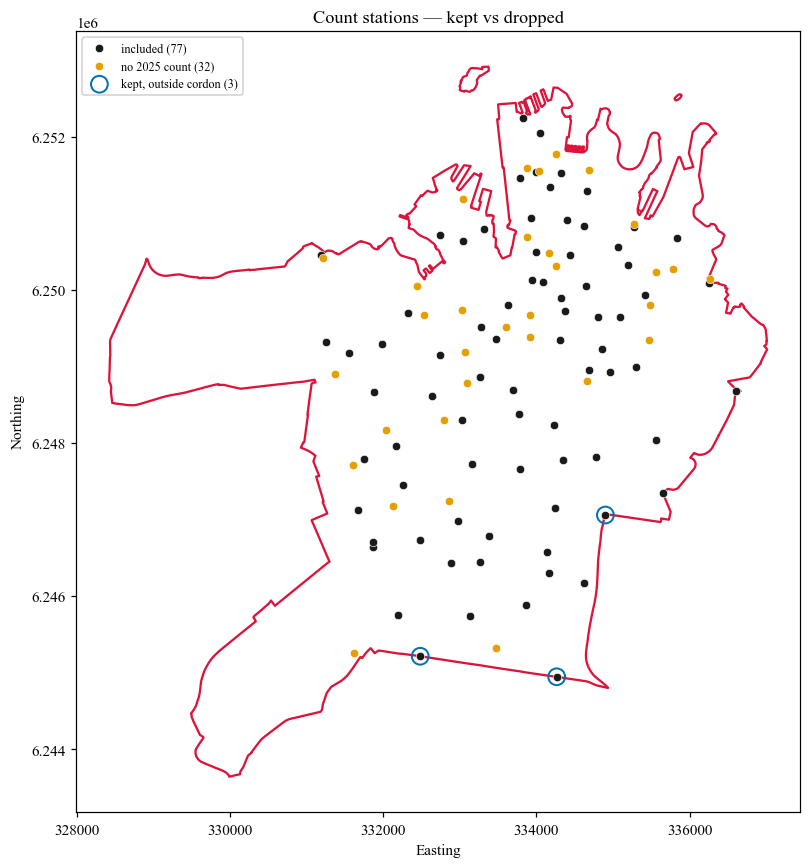

  member edges per station: min 1, median 4, max 10  | >8 edges at link(s) [10, 12]check ANG_DEG at complex junctions
  77 monitored sites -> 290 directed edges (mean 3.8/site, buffer 15 m); saved count_link_members.csv


In [13]:
print("=" * 60); print("SECTION D — Observed counts"); print("=" * 60)

# Load the raw count survey data and clean column names
survey = pd.read_csv(COUNT_SURVEY)
survey.columns = [c.strip() for c in survey.columns]
survey["Month"] = survey["Month"].astype(str).str.strip()

# v_obs_l = 1/2 * sum_rounds mean(h06, h07, h08)   (Eq 4.1, bidirectional)
# Filter for 2025 records in March and October
s25 = survey[(survey["Year"] == SURVEY_YEAR) & (survey["Month"].isin(SURVEY_MONTHS))].copy()
# Calculate the mean of the three morning peak hours across both survey rounds
s25["peak_mean"] = s25[PEAK_HOURS].apply(pd.to_numeric, errors="coerce").mean(axis=1)
# Create the bidirectional target flow (v_obs) by summing and dividing by 2
vobs = (s25.groupby("SiteID")["peak_mean"].sum() / 2.0).rename("v_obs").to_frame()
print(f"  sites with 2025 records: {len(vobs)}")

# Snap sites to the nearest edge of G_scc
# Snap ALL candidates (left-join keeps no-2025 sites in the funnel for diagnostics) ────
sites_all = sites_raw.merge(vobs, on="SiteID", how="left")
# Convert geographic coordinates (lat/lon) to the projected metric CRS
_spt = gpd.GeoSeries([Point(r.lon, r.lat) for r in sites_all.itertuples()],
                     crs=CENTROID_CRS).to_crs(PROJECTED_CRS)
sites_all["x_m"], sites_all["y_m"] = _spt.x.values, _spt.y.values
# Find the nearest edge in the simplified network for every count station
_eids, _dists = ox.distance.nearest_edges(Gr, sites_all["x_m"].values,
                                          sites_all["y_m"].values, return_dist=True)
sites_all["u"] = [e[0] for e in _eids]; sites_all["v"] = [e[1] for e in _eids]
sites_all["k"] = [e[2] for e in _eids]; sites_all["snap_m"] = _dists
sites_all["has_2025"] = sites_all["v_obs"].notna()

# ── Manual re-snap BEFORE `mon`/count_link_members are built ──────────────────
# Site 21 (Harbour Bridge) auto-snaps to a footway/steps or to Watson Rd; its real
# corridor is the adjacent Harbour Bridge Cycleway. Force it onto the cycleway edge
# so the monitored link, the corridor members and v_obs all key off the cycleway.
# MUST run here (before `mon` and count_link_members.csv are assembled below).
_FORCE_SNAP = {21: (11583060113, 11583060140, 0)}      # SiteID -> (u, v, k) cycleway edge
for _sid, (_u, _v, _k) in _FORCE_SNAP.items():
    _m = sites_all["SiteID"] == _sid
    if _m.any():
        if not Gr.has_edge(_u, _v, _k):
            # Guard against underlying OSM changes breaking the hardcoded manual override
            raise AssertionError(f"[override] edge ({_u},{_v},{_k}) not in Gr - site {_sid} cannot be "
                                 f"re-snapped. The OSM snapshot changed; update _FORCE_SNAP before continuing.")
        else:
            # Overwrite the auto-snapped edge with the manual override edge
            sites_all.loc[_m, ["u", "v", "k"]] = [_u, _v, _k]
            sites_all.loc[_m, "snap_m"] = 0.0
            print(f"  [override] site {_sid} re-snapped to cycleway edge ({_u},{_v},{_k})")
    else:
        print(f"  [override] site {_sid} not present in sites_all — check SiteID")

# Filter stations based on valid 2025 counts and falling within the 45m snap tolerance
sites_all["included"] = sites_all["has_2025"] & (sites_all["snap_m"] <= COUNT_SNAP_TOL_M)
sites = sites_all[sites_all["included"]].copy()          # identical to the old inner+filter
print(f"  {len(sites)} of {len(sites_all)} candidate sites kept: a 2025 record AND snap "
      f"<= {COUNT_SNAP_TOL_M:.0f} m of G_scc (§4.2.3). Monitored count below should read 77.")


# ── Diagnostic A: reconcile the exclusion funnel with the real filter ──
# The authoritative keep rule is `included` = has_2025 AND snap<=TOL — nothing
# else. `reason` mirrors it exactly, so the funnel's "included" count equals
# len(sites) (77). in_cordon is an INFORMATIONAL flag; inclusion is gated purely by
# has_2025 AND snap<=TOL, so a few kept sites sit just outside the drawn cordon polygon.
_cordon = _cp if "_cp" in dir() else \
          gpd.read_file(DATA_RAW/"study_area_cordon.gpkg").to_crs(PROJECTED_CRS).union_all()
sites_all["in_cordon"] = [_cordon.contains(Point(x, y))
                          for x, y in zip(sites_all.x_m, sites_all.y_m)]
_offlbl = f"off-network (>{COUNT_SNAP_TOL_M:.0f} m)"
def _why(r):
    if r.included:     return "included"
    if not r.has_2025: return "no 2025 count"
    return _offlbl                       # has a 2025 record but snapped beyond TOL
sites_all["reason"] = sites_all.apply(_why, axis=1)

print("\n  Exclusion funnel (mirrors the keep rule: has_2025 AND snap<=TOL):")
for _r, _n in sites_all["reason"].value_counts().items():
    print(f"    {_r:<22} {_n:>3}")
_n_out = int((sites_all["included"] & ~sites_all["in_cordon"]).sum())
if _n_out:
    print(f"  note: {_n_out} kept site(s) sit just outside the drawn cordon polygon "
          f"(kept anyway — inclusion is snap-based, not cordon-based).")
_drop = sites_all[~sites_all["included"]].sort_values(["reason", "snap_m"])
if len(_drop):
    print(f"\n  {len(_drop)} excluded stations:")
    for r in _drop.itertuples():
        print(f"    {str(r.SiteID):<12} ({r.lon:.5f}, {r.lat:.5f})  "
              f"snap={r.snap_m:6.0f} m  → {r.reason}")

# ── Diagnostic B: where kept vs dropped stations sit ──────────────────
import matplotlib.pyplot as plt
import geopandas as gpd

# Set Times New Roman globally for this plot
plt.rcParams["font.family"] = "Times New Roman"

_fig, _ax = plt.subplots(figsize=(8, 8))
gpd.GeoSeries([_cordon], crs=PROJECTED_CRS).boundary.plot(ax=_ax, color="crimson", lw=1.5, zorder=5)
_pal = {"included":"#1a1a1a", "no 2025 count":"#e69f00", _offlbl:"#d55e00"}
for _r, _c in _pal.items():
    _s = sites_all[sites_all["reason"] == _r]
    if len(_s):
        _ax.scatter(_s.x_m, _s.y_m, s=30, c=_c, edgecolor="white", linewidth=0.4,
                    label=f"{_r} ({len(_s)})", zorder=6)
# ring any kept site outside the drawn cordon (informational; not an exclusion)
_out = sites_all[sites_all["included"] & ~sites_all["in_cordon"]]
if len(_out):
    _ax.scatter(_out.x_m, _out.y_m, s=120, facecolors="none", edgecolor="#0072b2",
                linewidth=1.3, zorder=7, label=f"kept, outside cordon ({len(_out)})")
_ax.set_aspect("equal"); _ax.legend(loc="upper left", fontsize=8, framealpha=0.9)
_ax.set_title("Count stations — kept vs dropped"); _ax.set_xlabel("Easting"); _ax.set_ylabel("Northing")
plt.tight_layout(); plt.show()

# ── Corridor-level counter matching: one site -> its whole cross-section ──
# A count station measures a corridor (both directions + side-by-side bike/road ways),
# so map each site to every directed edge within BUF_M whose bearing is parallel or
# anti-parallel to the snapped edge (excludes cross streets), deduped to the nearest site.
BUF_M, ANG_DEG = 15.0, 35.0

mon = (sites.groupby(["u", "v", "k"])
             .agg(v_obs=("v_obs", "mean"), n_sites=("SiteID", "nunique")).reset_index())

_edges = list(Gr.edges(keys=True))          # Gr is projected -> x/y are metres
_eu = np.array([e[0] for e in _edges]); _ev = np.array([e[1] for e in _edges]); _ek = np.array([e[2] for e in _edges])
_ux = np.array([Gr.nodes[u]["x"] for u in _eu]); _uy = np.array([Gr.nodes[u]["y"] for u in _eu])
_vx = np.array([Gr.nodes[v]["x"] for v in _ev]); _vy = np.array([Gr.nodes[v]["y"] for v in _ev])
_mx, _my = (_ux + _vx) / 2, (_uy + _vy) / 2
_brg = np.degrees(np.arctan2(_vy - _uy, _vx - _ux)) % 360
def _angdiff(a, b): d = abs((a - b) % 360); return min(d, 360 - d)

# Identify parallel and anti-parallel member edges for the screenline
mon_index, mon_reverse, _best = {}, {}, {}
for i, r in mon.iterrows():
    u, v = int(r.u), int(r.v)
    px, py = (Gr.nodes[u]["x"] + Gr.nodes[v]["x"]) / 2, (Gr.nodes[u]["y"] + Gr.nodes[v]["y"]) / 2
    pb = np.degrees(np.arctan2(Gr.nodes[v]["y"] - Gr.nodes[u]["y"],
                               Gr.nodes[v]["x"] - Gr.nodes[u]["x"])) % 360
    dd = np.hypot(_mx - px, _my - py)
    for e in np.where(dd < BUF_M)[0]:
        if min(_angdiff(_brg[e], pb), _angdiff(_brg[e], (pb + 180) % 360)) > ANG_DEG:
            continue
        key = (int(_eu[e]), int(_ev[e]), int(_ek[e]))
        if key in _best and _best[key] <= dd[e]:
            continue
        mon_index[key] = i; _best[key] = dd[e]

pd.DataFrame([(i, a, b, k) for (a, b, k), i in mon_index.items()],
             columns=["link_idx", "u", "v", "k"]).to_csv(
    DATA_PROCESSED / "count_link_members.csv", index=False)
_per = pd.Series(list(mon_index.values())).value_counts()
print(f"  member edges per station: min {_per.min()}, median {int(_per.median())}, max {_per.max()}"
        + (f"  | >8 edges at link(s) {sorted(_per[_per > 8].index.tolist())}check ANG_DEG at complex junctions"
         if (_per > 8).any() else ""))
assert set(_per.index) == set(range(len(mon))), "a monitored station has no member edge"
print(f"  {len(mon)} monitored sites -> {len(mon_index)} directed edges "
      f"(mean {len(mon_index)/max(len(mon),1):.1f}/site, buffer {BUF_M:.0f} m); saved count_link_members.csv")

# E — Seed O-D and polygon-node distribution (§4.2.4)


Load the snapped seed O-D matrix and distribute each zone's demand uniformly over every network node
inside its polygon (the $m\times n$ representation). A single representative node (nearest the centroid)
is also recorded per zone for the Stage-2 routing.


In [14]:
print("=" * 60); print("SECTION E — Seed O-D + node distribution"); print("=" * 60)

# Keep `movement` from NB 03's snapped file so the four classes
# (inbound_internal / inbound_external / outbound) flow through NB 04
# Load the pre-processed O-D matrix and clean the origin (o) and destination (d) string formats
od_main = (pd.read_csv(OD_SNAPPED)[["origin_point", "dest_point", "trips", "movement"]]
             .rename(columns={"origin_point": "o", "dest_point": "d"}))
for c in ["o", "d"]:
    od_main[c] = od_main[c].astype(str).str.replace(r"\.0$", "", regex=True)
# Filter out empty OD pairs
od_main = od_main[od_main["trips"] > 0].reset_index(drop=True)
print(f"  snapped inbound (internal+external) + outbound seed: "
      f"{len(od_main):,} pairs, {od_main['trips'].sum():,.0f} trips")
print(f"  movement labels in od_main: {od_main['movement'].value_counts().to_dict()}")

# One combined centroid lookup (+ cordon entry points if present)
# Merge SA1, DZN, and SA2 centroids into a single coordinate dictionary
lookup = {**sa1_lookup, **dzn_lookup, **sa2_lookup}
ep_path = DATA_RAW / "cordon_entry_points.csv"
if ep_path.exists():
    ep = pd.read_csv(ep_path)
    xc = next(c for c in ep.columns if c.lower() in ("x", "lon", "longitude", "lng"))
    yc = next(c for c in ep.columns if c.lower() in ("y", "lat", "latitude"))
    cc = next(c for c in ep.columns if c not in (xc, yc))
    for _, r in ep.iterrows():
        lookup[str(r[cc]).replace(".0", "").strip()] = (float(r[xc]), float(r[yc]))
    print(f"  + {len(ep)} cordon entry points")

# ── Polygon-NODE distribution: every graph node inside the polygon is a candidate
# origin/destination with UNIFORM weight, including purely-internal nodes whose
# incident edges cross the polygon boundary. ──
# Extract all node coordinates from the routable graph as a GeoDataFrame
nodes_gdf = ox.graph_to_gdfs(Gr, edges=False).reset_index()
# Normalise node-id column name across OSMnx versions
_nid_col = "osmid" if "osmid" in nodes_gdf.columns else nodes_gdf.columns[0]
nodes_gdf = nodes_gdf[[_nid_col, "geometry"]].rename(columns={_nid_col: "node_id"})

# Identify which zones actually have demand in the OD matrix
inside_codes = set(str(int(c)) for c in pd.read_csv(DZN_INSIDE_CSV)["DZN_CODE_2016"])
need = set(od_main["o"]) | set(od_main["d"])

# Project zone polygons and combine them into a single GeoDataFrame
sa1_shp_m = sa1_shp.to_crs(PROJECTED_CRS); sa1_shp_m["_code"] = sa1_shp["_code"]
dzn_shp_m = dzn_shp.to_crs(PROJECTED_CRS)
zones = gpd.GeoDataFrame(pd.concat([
    sa1_shp_m[sa1_shp_m["_code"].isin(need)][["_code", "geometry"]],
    dzn_shp_m[dzn_shp_m["_code"].isin(need & inside_codes)][["_code", "geometry"]],
], ignore_index=True), geometry="geometry", crs=PROJECTED_CRS)

# Spatial join: point-in-polygon. Every node whose geometry falls inside the polygon
# is a candidate, including purely-internal nodes.
j = gpd.sjoin(nodes_gdf, zones, predicate="within")
code2nodes = {}
for code_val, grp in j.groupby("_code"):
    uniq = set(int(n) for n in grp["node_id"])
    if uniq:
        # Assign a uniform fractional weight to every node in the polygon
        w = 1.0 / len(uniq)         # uniform allocation across all nodes
        code2nodes[code_val] = {nd: w for nd in uniq}

# Any remaining code (entry points, external SA2, unmatched) -> single nearest node
# Snap zones lacking polygon coverage directly to the nearest network node
single = [c for c in need if c not in code2nodes and c in lookup]
if single:
    cx = gpd.GeoSeries([Point(*lookup[c]) for c in single], crs=CENTROID_CRS).to_crs(PROJECTED_CRS)
    sn = ox.distance.nearest_nodes(Gr, cx.x.values, cx.y.values)
    for c, nd in zip(single, sn):
        code2nodes[c] = {int(nd): 1.0}
        
# Representative node per zone for Stage 2 (k-shortest on m x n sub-pairs is infeasible):
# the zone's own node nearest its polygon centroid (deterministic, standard centroid connector).
_zc = zones.dissolve(by="_code").geometry.centroid
rep_node = {}
for code_val, nds in code2nodes.items():
    nds = sorted(nds)
    if len(nds) == 1 or code_val not in _zc.index:
        # If only one node exists or no centroid is available, default to the first node
        rep_node[code_val] = nds[0] if len(nds) == 1 else min(nds); continue
    c = _zc[code_val]
    # Calculate squared Euclidean distance to find the node closest to the polygon centroid
    rep_node[code_val] = min(nds, key=lambda n: (Gr.nodes[n]["x"] - c.x) ** 2 + (Gr.nodes[n]["y"] - c.y) ** 2)
print(f"  {len(code2nodes)} zone codes resolved to graph nodes "
      f"(uniform over all internal + boundary nodes within each polygon)")

# ── Diagnostic: node-count distribution per zone ──
_sz = [len(v) for v in code2nodes.values()]
if _sz:
    import numpy as _np
    print(f"  nodes-per-zone: min={min(_sz)}, median={int(_np.median(_sz))}, "
          f"mean={_np.mean(_sz):.1f}, max={max(_sz)}")

SECTION E — Seed O-D + node distribution
  snapped inbound (internal+external) + outbound seed: 1,590 pairs, 3,040 trips
  movement labels in od_main: {'inbound_external': 1443, 'inbound_internal': 121, 'outbound': 26}
  + 30 cordon entry points
  292 zone codes resolved to graph nodes (uniform over all internal + boundary nodes within each polygon)
  nodes-per-zone: min=1, median=22, mean=44.9, max=305


# F — Through-trip plausibility filtering


Route each outside-to-outside candidate through the network and keep it only if its least-cost path
actually crosses the cordon and its in-network length is within the 99.5th-percentile distance cap — so
implausibly long through-trips don't distort the assignment.


In [15]:
print("=" * 60); print("SECTION F — Through-trip filter (least-cost path)"); print("=" * 60)

# Load the raw through-trip demand generated in Notebook 03
od_through_raw = pd.read_csv(OD_THROUGH_RAW)
# Standardise string formatting for origin and destination codes
for c in ["origin", "destination"]:
    od_through_raw[c] = od_through_raw[c].astype(str).str.replace(r"\.0$", "", regex=True)

# Outside-DZN centroids for through destinations (projected, then back to lon/lat)
# For destinations that are DZNs located outside the central lookup array, calculate their centroids
out_dzn = set(od_through_raw["destination"]) - set(dzn_lookup)
if out_dzn:
    sub = dzn_shp[dzn_shp["_code"].isin(out_dzn)].to_crs(PROJECTED_CRS)
    cll = sub.set_index("_code").geometry.centroid.to_crs(CENTROID_CRS)
    for code_val, pt in cll.items():
        lookup[str(code_val)] = (pt.x, pt.y)

# Filter for through-trip candidates where both endpoints have valid centroid coordinates
cand = od_through_raw[od_through_raw["origin"].isin(lookup)
                      & od_through_raw["destination"].isin(lookup)].copy()
print(f"  through candidates with endpoints located: {len(cand):,}")

# Snap endpoints to nearest N_full node
# Convert geographic coordinates to projected metric system and find the nearest network node for each endpoint
opts = gpd.GeoSeries([Point(*lookup[c]) for c in cand["origin"]], crs=CENTROID_CRS).to_crs(PROJECTED_CRS)
dpts = gpd.GeoSeries([Point(*lookup[c]) for c in cand["destination"]], crs=CENTROID_CRS).to_crs(PROJECTED_CRS)
o_nodes = ox.distance.nearest_nodes(Gr, opts.x.values, opts.y.values)
d_nodes = ox.distance.nearest_nodes(Gr, dpts.x.values, dpts.y.values)
node_xy = {n: (Gr.nodes[n]["x"], Gr.nodes[n]["y"]) for n in Gr.nodes}

# ── Pass 1: route every candidate once; record path length + cordon crossing ──
routed_info = []          # List to store tuples of (orig_index, length_km, crosses_cordon)
for n_done, ((idx, _row), on, dn) in enumerate(zip(cand.iterrows(), o_nodes, d_nodes), 1):
    if n_done % 100 == 0:
        print(f"    routed {n_done}/{len(cand)} through candidates...")
    try:
        # Route the candidate along the simplest lowest-cost path
        path = nx.shortest_path(G_full_simple, int(on), int(dn), weight="cost")
    except (nx.NetworkXNoPath, nx.NodeNotFound):
        # Skip if no valid path exists in the network
        continue
    if len(path) < 2:                      # origin == destination node
        continue
    # Convert path node sequence to a geographic LineString to calculate metric distance and cordon intersection
    line = LineString([node_xy[n] for n in path])
    routed_info.append((idx, line.length / 1000.0, line.intersects(cordon_polygon)))

# ── Length cap = 99.5th-pct of snapped external-trip distances (§4.2.1) ──
# Priority: manual override  ->  value persisted by NB03  ->  computed here.
# To let NB03 drive it, have NB03 write the number to through_trip_p995_km.txt:
#     (DATA_PROCESSED / "through_trip_p995_km.txt").write_text(f"{p995:.4f}")
MAX_THROUGH_KM_OVERRIDE = globals().get("MAX_THROUGH_KM_OVERRIDE", None)
_lens = np.array([L for _, L, _ in routed_info], dtype=float)
_p995_file = DATA_PROCESSED / "through_trip_p995_km.txt"
if MAX_THROUGH_KM_OVERRIDE is not None:
    MAX_THROUGH_KM = float(MAX_THROUGH_KM_OVERRIDE); _src = "manual override"
elif _p995_file.exists():
    MAX_THROUGH_KM = float(_p995_file.read_text().strip()); _src = _p995_file.name
elif _lens.size:
    # Compute the dynamic 99.5th percentile length cap from routed candidates
    MAX_THROUGH_KM = float(np.percentile(_lens, 99.5)); _src = "computed p99.5 of routed external-trip lengths"
else:
    MAX_THROUGH_KM = 14.7; _src = "fallback (no routed lengths)"
print(f"  through-trip length cap = {MAX_THROUGH_KM:.2f} km  ({_src})")

# ── Pass 2: keep candidates whose path crosses the cordon and is within the cap ──
# Filter out trips that do not enter the study area or that exceed the maximum plausible distance
keep_rows = [idx for idx, L, crosses in routed_info if crosses and L <= MAX_THROUGH_KM]
_n_cross = sum(1 for _, _, c in routed_info if c)
print(f"  THROUGH FUNNEL: candidates {len(cand):,} -> routable with distinct end nodes {len(routed_info):,} "
      f"(dropped {len(cand)-len(routed_info):,}: both ends snap to the same node or no path) -> "
      f"path crosses cordon {_n_cross:,} -> within cap {len(keep_rows):,}")
print("  NOTE: path length is the in-network leg (the network ends 500 m beyond the cordon), and the cap is the\n"
      "        p99.5 of these same candidates, so it removes ~0.5% by construction - say so in the thesis.")
od_through = cand.loc[keep_rows].copy(); od_through["movement"] = "through"
print(f"  through retained (path crosses cordon, <= {MAX_THROUGH_KM:.2f} km): {len(od_through):,}")

SECTION F — Through-trip filter (least-cost path)
  through candidates with endpoints located: 765
    routed 100/765 through candidates...
    routed 200/765 through candidates...
    routed 300/765 through candidates...
    routed 400/765 through candidates...
    routed 500/765 through candidates...
    routed 600/765 through candidates...
    routed 700/765 through candidates...
  through-trip length cap = 11.24 km  (computed p99.5 of routed external-trip lengths)
  THROUGH FUNNEL: candidates 765 -> routable with distinct end nodes 416 (dropped 349: both ends snap to the same node or no path) -> path crosses cordon 263 -> within cap 260
  NOTE: path length is the in-network leg (the network ends 500 m beyond the cordon), and the cap is the
        p99.5 of these same candidates, so it removes ~0.5% by construction - say so in the thesis.
  through retained (path crosses cordon, <= 11.24 km): 260


## F.1 Merge demand and resolve node sub-pairs

Merge the inbound/outbound seed with the retained through trips, snap every zone to its network nodes, and
expand each pair into proportionally-weighted node sub-pairs. Identical origin/destination nodes are
re-pointed to the next-nearest node so every pair has a real path.


In [16]:
# Combine inbound (internal + external) + outbound seed with retained through; resolve to node sub-pairs
# Extract relevant columns from the through-trip matrix and rename them to match the main OD matrix
od_thr = od_through[["origin", "destination", "trips"]].rename(columns={"origin": "o", "destination": "d"})
od_thr["movement"] = "through"
# Concatenate the main matrix and the through-trip matrix into a single comprehensive OD DataFrame
od = pd.concat([od_main, od_thr], ignore_index=True)
# Drop any OD pairs that have zero recorded trips to optimise routing performance
od = od[od["trips"] > 0].reset_index(drop=True)

# make sure every through endpoint has a node mapping
for c in set(od["o"]) | set(od["d"]):
    if c not in code2nodes and c in lookup:
        # Project the geographic centroid to the local metric coordinate reference system
        cx = gpd.GeoSeries([Point(*lookup[c])], crs=CENTROID_CRS).to_crs(PROJECTED_CRS)
        # Snap the projected centroid to the nearest physical node on the OpenStreetMap network
        nd = ox.distance.nearest_nodes(Gr, cx.x.values, cx.y.values)[0]
        # Assign the snapped node a 100% (1.0) probability weight for this zone
        code2nodes[c] = {int(nd): 1.0}

# Filter to retain only OD pairs where both ends have successfully mapped to network nodes
pair_ids = od[od["o"].isin(code2nodes) & od["d"].isin(code2nodes)].reset_index(drop=True)
n_pairs = len(pair_ids)
n_vec = pair_ids["trips"].to_numpy(float)

# Distribute demand proportionally across node sub-pairs if a zone maps to multiple boundary nodes
rows = []
for pid, r in pair_ids.iterrows():
    on, dn = code2nodes[r["o"]], code2nodes[r["d"]]
    acc = defaultdict(float)
    for a, wa in on.items():
        for b, wb in dn.items():
            if a != b:
                # Accumulate weighted probabilities for routing between distinct nodes
                acc[(a, b)] += wa * wb
    s = sum(acc.values())
    if s <= 0:
        continue
    for (a, b), w in acc.items():
        # Append the fractional weight of this specific node-to-node sub-pair
        rows.append((pid, a, b, w / s))
subpairs = pd.DataFrame(rows, columns=["pair_id", "o_node", "d_node", "frac"])

# Stage-2 representative node pair (see Section E). If both ends land on the same node,
# use the destination zone's next-nearest node so every pair has a real path.
for c in set(pair_ids["o"]) | set(pair_ids["d"]):
    if c not in rep_node and c in code2nodes:
        # Select the highest-probability primary node to represent the zone
        rep_node[c] = sorted(code2nodes[c])[0]
o_rep = pair_ids["o"].map(rep_node); d_rep = pair_ids["d"].map(rep_node)
_same = (o_rep == d_rep)

# Loop through trips where the origin and destination snapped to the exact same network node
for pid in pair_ids.index[_same]:
    # Identify alternate network nodes associated with the destination zone
    alt = [n for n in sorted(code2nodes[pair_ids.at[pid, "d"]]) if n != o_rep[pid]]
    if alt:
        c = gpd.GeoSeries([Point(Gr.nodes[o_rep[pid]]["x"], Gr.nodes[o_rep[pid]]["y"])]).iloc[0]
        # Relocate the destination to the alternate node that is geographically closest to the origin node
        d_rep[pid] = min(alt, key=lambda n: (Gr.nodes[n]["x"] - c.x) ** 2 + (Gr.nodes[n]["y"] - c.y) ** 2)
# Overwrite the OD matrix with the finalised, guaranteed-distinct origin and destination nodes
pair_ids["o_node"] = o_rep.astype("Int64"); pair_ids["d_node"] = d_rep.astype("Int64")
print(f"  representative node pairs: {int(_same.sum())} same-node pairs re-pointed; "
      f"remaining identical o/d: {int((pair_ids.o_node == pair_ids.d_node).sum())}")
print(f"  seed: {n_pairs:,} OD pairs ({n_vec.sum():,.0f} trips) -> {len(subpairs):,} node sub-pairs")

  representative node pairs: 0 same-node pairs re-pointed; remaining identical o/d: 0
  seed: 1,850 OD pairs (4,264 trips) -> 745,446 node sub-pairs


## F.2 Zone representative sampling for Stage 2

Sample up to `N_REP` representative nodes per zone and freeze them to `zone_rep_nodes.json`, so Notebooks
05/07/09b all route the **same** sub-pairs (none re-sample). A dry-run sizing shows the routing scale.


In [17]:
# ── Zone-spread representative nodes for Stage 2 ──
# Stage 1 (above) spreads each zone over ALL its nodes (m x n AON). Stage 2 (NB05) mirrors that by routing
# k-shortest on a SAMPLE of up to tc.N_REP nodes per zone. Freeze the sample here so NB05/NB07/NB09b all
# read the SAME nodes (none re-sample).
import json as _json

zone_reps = tc.sample_zone_reps(code2nodes, rep_node, n_rep=tc.N_REP, seed=tc.REP_SEED)
tc.ZONE_REP_JSON.write_text(_json.dumps(zone_reps))

_sz = [len(v) for v in zone_reps.values()]
print(f"  zone_rep_nodes.json: {len(zone_reps)} zones, N_REP={tc.N_REP}; "
      f"nodes/zone min {min(_sz)} median {int(np.median(_sz))} max {max(_sz)}")

# Dry-run sizing: how many unique sub-pairs Stage 2 will route at this N_REP.
_prev = pair_ids[["o", "d", "o_node", "d_node"]].copy()
_prev["pair_idx"] = range(len(_prev))
_exp, _asm, _rep = tc.expand_pairs(_prev, reps=zone_reps)
_links = sum(len(a) for a in _asm)
_empty = sum(1 for a in _asm if not a)
print(f"  expand_pairs preview: {len(_prev):,} O-D pairs -> {len(_exp):,} unique sub-pairs to route "
      f"(was {len(_prev):,} single-node); {_links:,} (pair,sub-pair) links; {_empty} pairs with no sub-pair")
print(f"  -> routing cost scales with the {len(_exp):,} figure; drop tc.N_REP if it is too large for NB09b's sweeps")


  zone_rep_nodes.json: 492 zones, N_REP=5; nodes/zone min 1 median 5 max 5
  expand_pairs preview: 1,850 O-D pairs -> 8,721 unique sub-pairs to route (was 1,850 single-node); 10,489 (pair,sub-pair) links; 0 pairs with no sub-pair
  -> routing cost scales with the 8,721 figure; drop tc.N_REP if it is too large for NB09b's sweeps


# G — Neutral AON assignment on $N_{full}$ (§4.1, first outer iteration)


Route all demand by grade-adjusted-time all-or-nothing (single-source Dijkstra per origin), accumulate
link flows, and build the neutral incidence matrix `A_neutral` (one screenline crossing per monitored
station) plus the seed flows `f_seed`.


In [18]:
print("=" * 60); print("SECTION G — Neutral AON assignment on N_full"); print("=" * 60)

# Initialise data structures to store link-level flows and sparse matrix coordinate lists
flow = defaultdict(float)
A_rows, A_cols, A_vals = [], [], []
by_origin = defaultdict(list)

# Group sub-pairs by their origin node for efficient single-source shortest path routing
for t in subpairs.itertuples(index=False):
    by_origin[t.o_node].append((int(t.pair_id), int(t.d_node), float(t.frac)))

routed = dropped = 0
origins = list(by_origin)

# Iterate through each unique origin node to compute shortest paths across the network
for i, onode in enumerate(origins):
    if (i + 1) % 100 == 0:
        print(f"    {i + 1}/{len(origins)} origins routed...")
    try:
        # Compute single-source shortest paths from the origin to all network nodes using grade-adjusted cost
        _, paths = nx.single_source_dijkstra(G_full_simple, onode, weight="cost")
    except nx.NodeNotFound:
        # Drop sub-pairs if the origin node is missing from the network graph
        dropped += len(by_origin[onode]); continue

    # Process each destination and fractional demand associated with the current origin
    for pid, dnode, frac in by_origin[onode]:
        path = paths.get(dnode)
        if not path:
            # Drop the sub-pair if no valid path exists between the origin and destination
            dropped += 1; continue
        routed += 1
        trips = n_vec[pid]
        _hit = set()
        
        # Accumulate traffic volumes across each edge along the shortest path
        for a, b in zip(path[:-1], path[1:]):
            kk = G_full_simple[a][b].get("_orig_key", 0)
            flow[(a, b, kk)] += frac * trips
            mi = mon_index.get((a, b, kk))
            if mi is not None:
                _hit.add(mi)
        # Record screenline monitoring station crossings for the incidence matrix (one crossing per site)
        for mi in _hit:                    
            A_rows.append(mi); A_cols.append(pid); A_vals.append(frac)

# Construct the sparse baseline incidence matrix and compute initial modelled seed flows at count locations
A_neutral = sparse.coo_matrix((A_vals, (A_rows, A_cols)), shape=(len(mon), n_pairs)).tocsr()
f_seed = np.asarray(A_neutral.dot(n_vec)).ravel()
mon["f_seed"] = f_seed
print(f"  routed {routed:,} sub-pairs, dropped {dropped:,}")
print(f"  A_neutral: {A_neutral.shape}, {A_neutral.nnz:,} nnz")

SECTION G — Neutral AON assignment on N_full
    100/3318 origins routed...
    200/3318 origins routed...
    300/3318 origins routed...
    400/3318 origins routed...
    500/3318 origins routed...
    600/3318 origins routed...
    700/3318 origins routed...
    800/3318 origins routed...
    900/3318 origins routed...
    1000/3318 origins routed...
    1100/3318 origins routed...
    1200/3318 origins routed...
    1300/3318 origins routed...
    1400/3318 origins routed...
    1500/3318 origins routed...
    1600/3318 origins routed...
    1700/3318 origins routed...
    1800/3318 origins routed...
    1900/3318 origins routed...
    2000/3318 origins routed...
    2100/3318 origins routed...
    2200/3318 origins routed...
    2300/3318 origins routed...
    2400/3318 origins routed...
    2500/3318 origins routed...
    2600/3318 origins routed...
    2700/3318 origins routed...
    2800/3318 origins routed...
    2900/3318 origins routed...
    3000/3318 origins routed...
    

# H — Stage 1 GLS: calibrate $t$ (Bell 1991, §4.5)

$\min (t-n)'Q^{-1}(t-n) + (v_{obs}-A t)'W^{-1}(v_{obs}-A t)$, $t\ge 0$, with $Q=\sigma_0^2 I$ and $W$ the
per-link count variance over 2022–2025.

Count dispersion $W$ is built, a stratified 70/30 train/held-out split is drawn on $v_{obs}$, and $\hat t$
is fitted on the **training stations only** to keep the held-out set untouched until Notebook 06.


In [19]:
print("=" * 60); print("SECTION H — Stage-1 GLS (TRAINING stations only)"); print("=" * 60)
v_obs = mon["v_obs"].to_numpy(float)
L     = len(mon)
mon_links = mon.reset_index().rename(columns={"index": "link_idx"})
mon_links["link_idx"] = range(L)

# Count-dispersion matrix W (per-link variance of round-mean peak counts, 2022-2025).
W, _n_own = tc.build_W(tc.load_survey(COUNT_SURVEY), tc.site_to_link(sites, mon_links), L)
print(f"  W: {_n_own}/{L} links with own variance; median sd {np.sqrt(np.median(W)):.1f} trips/hr")

# Stratified 70/30 train/held-out split on v_obs quartiles (seed 42), persisted for every downstream notebook.
train_mask = tc.make_split(v_obs)
print(f"  split: train {int(train_mask.sum())} | held-out {int((~train_mask).sum())}  (seed {tc.SPLIT_SEED})")
print("  LEAKAGE POLICY: only training stations are fitted or evaluated before NB07 freezes pi*.")

def solve_gls(A, n, vobs, Wd, mask, sigma2=SIGMA2):       # thin wrapper, name kept for downstream ablation cells
    return tc.solve_gls(A, n, vobs, Wd, mask, sigma2)

# Solve Bell's constrained GLS for the calibrated demand t on the training stations only.
t_hat = solve_gls(A_neutral, n_vec, v_obs, W, train_mask)
f_cal = np.asarray(A_neutral.dot(t_hat)).ravel()
mon["f_cal"] = f_cal

# Training-station fit: seed vs Stage-1 calibrated.
m_seed = tc.metrics(f_seed[train_mask], v_obs[train_mask])
m_cal  = tc.metrics(f_cal[train_mask],  v_obs[train_mask])
print(f"  t total {t_hat.sum():,.0f}  (x{t_hat.sum() / n_vec.sum():.2f} vs seed); "
      f"median t/n {np.median(t_hat[n_vec > 0] / n_vec[n_vec > 0]):.2f}")
print(f"  seed  (train): {tc.fmt_m(m_seed)}")
print(f"  Stage1(train): {tc.fmt_m(m_cal)}")


SECTION H — Stage-1 GLS (TRAINING stations only)
  W: 77/77 links with own variance; median sd 10.8 trips/hr
  split: train 53 | held-out 24  (seed 42)
  LEAKAGE POLICY: only training stations are fitted or evaluated before NB07 freezes pi*.
  t total 3,714  (x0.87 vs seed); median t/n 1.00
  seed  (train): meanGEH 9.00 | GEH<5 24.5% | RMSE 128.0 | R2 0.187 (CoD -0.190) | bias -29% | n=53
  Stage1(train): meanGEH 6.35 | GEH<5 54.7% | RMSE 107.4 | R2 0.391 (CoD 0.162) | bias -49% | n=53


## H.1 Stage-1 network flows (for the progression flow map)

If enabled, re-route the calibrated demand to export directed link flows (`stage1_edge_flows.csv`) for the
Stage-1 panel of the flow map in Notebook 07.


In [20]:
# Optional second AON pass weighted by the calibrated demand t, to export directed edge flows for the
# Stage-1 panel of the Notebook 07 flow map.
if STAGE1_EDGE_FLOWS:
    flow_t = defaultdict(float)
    for i, onode in enumerate(origins):
        if (i + 1) % 500 == 0: print(f"    {i + 1}/{len(origins)} origins")
        try:
            _, paths = nx.single_source_dijkstra(G_full_simple, onode, weight="cost")
        except nx.NodeNotFound:
            continue
        for pid, dnode, frac in by_origin[onode]:
            path = paths.get(dnode)
            if not path: continue
            w = frac * t_hat[pid]                         # calibrated trips on this sub-pair
            for a, b in zip(path[:-1], path[1:]):
                flow_t[(a, b)] += w
    pd.DataFrame([dict(u=a, v=b, flow_t=x) for (a, b), x in flow_t.items()]).to_csv(
        DATA_PROCESSED / "stage1_edge_flows.csv", index=False)
    print(f"  wrote stage1_edge_flows.csv ({len(flow_t):,} directed edges)")


    500/3318 origins
    1000/3318 origins
    1500/3318 origins
    2000/3318 origins
    2500/3318 origins
    3000/3318 origins
  wrote stage1_edge_flows.csv (23,766 directed edges)


# I — Save Stage-1 results


Serialise the Stage-1 outputs for the downstream notebooks: the neutral matrix, the calibrated trip table,
the monitored-link table, the count-snap table, the frozen train/held-out mask, and the flow-tagged graph.


In [21]:
print("=" * 60); print("SECTION I — Save"); print("=" * 60)

# Neutral incidence matrix for Stages 2-3.
sparse.save_npz(DATA_PROCESSED / "A_neutral.npz", A_neutral)

# Calibrated O-D trip table (seed + calibrated t + movement class), indexed by pair_idx.
_cols = ["o", "d", "o_node", "d_node", "trips"]
if "movement" in pair_ids.columns:
    _cols.append("movement")
out = pair_ids[_cols].copy()
out.index.name = "pair_idx"
out["n_seed"] = n_vec
out["t"] = t_hat
out.to_csv(DATA_PROCESSED / "od_calibrated_t.csv")

# Monitored-link attributes and the per-site snap table.
mon.to_csv(DATA_PROCESSED / "A_neutral_links.csv", index=True, index_label="link_idx")
sites.to_csv(DATA_PROCESSED / "count_link_snap.csv", index=False)

# Persist the frozen train/held-out mask (boolean length L, link_idx order) + metadata, so every
# downstream notebook uses the SAME split instead of regenerating it from a seed.
np.save(DATA_PROCESSED / "train_mask.npy", train_mask)
tc.TRAIN_MASK_NPY.parent.mkdir(parents=True, exist_ok=True)
_mask_meta = {
    "seed": int(tc.SPLIT_SEED),
    "frac": float(tc.SPLIT_FRAC),
    "n_strata": int(tc.N_STRATA),
    "L": int(L),
    "train": int(train_mask.sum()),
    "test": int((~train_mask).sum()),
    "stratified_on": "v_obs quartiles",
    "note": "Built in NB04 Section H; load with np.load('train_mask.npy').",
}
import json as _json
(DATA_PROCESSED / "train_mask.json").write_text(_json.dumps(_mask_meta, indent=2))
print(f"  wrote train_mask.npy ({_mask_meta['train']}/{_mask_meta['test']}) + train_mask.json")

# Tag the neutral bike flows onto the graph and export it for mapping.
nx.set_edge_attributes(Gr, 0.0, "bike_flow")
for (u, v, k), fl in flow.items():
    if Gr.has_edge(u, v) and k in Gr[u][v]:
        Gr[u][v][k]["bike_flow"] = fl
ox.save_graphml(Gr, filepath=str(DATA_PROCESSED / "network_neutral_flows.graphml"))

print("  wrote A_neutral.npz, od_calibrated_t.csv, A_neutral_links.csv,")
print("        count_link_snap.csv, network_neutral_flows.graphml")
if "movement" in out.columns:
    print(f"  movement labels in od_calibrated_t.csv: "
          f"{out['movement'].value_counts().to_dict()}")
else:
    print("  WARNING: od_calibrated_t.csv has no `movement` column — "
          "check NB 04 Section F edit (od_thr['movement'] = 'through').")


SECTION I — Save
  wrote train_mask.npy (53/24) + train_mask.json
  wrote A_neutral.npz, od_calibrated_t.csv, A_neutral_links.csv,
        count_link_snap.csv, network_neutral_flows.graphml
  movement labels in od_calibrated_t.csv: {'inbound_external': 1443, 'through': 260, 'inbound_internal': 121, 'outbound': 26}


# J — Station names for every figure and table


Build a clean label for each monitored station — from an override file, then the site register, then the
OSM street names at the screenline — resolving duplicates with the Site ID, and export `station_names.csv`.


In [22]:
def _flat_name(x):
    # Flatten list attributes or return string representations of road names
    x = x[0] if isinstance(x, list) else x
    return str(x) if x is not None and str(x) not in ("", "nan", "None") else None

_reg = sites_raw.copy(); _reg.columns = [c.strip() for c in _reg.columns]
_ncol = next((c for c in _reg.columns if c.lower().replace(" ", "_") in tc.NAME_COLS), None)
_regmap = dict(zip(_reg["SiteID"], _reg[_ncol].astype(str))) if _ncol else {}

# Load manual station name overrides if the override CSV file exists
_ovr = DATA_RAW / "station_names_override.csv"
_ovmap = dict(pd.read_csv(_ovr)[["SiteID", "label"]].itertuples(index=False)) if _ovr.exists() else {}
print(f"  register name column: {_ncol!r} | overrides: {len(_ovmap)}")

_members_by_link = defaultdict(list)
for (a, b, k_), li in mon_index.items(): _members_by_link[li].append((a, b, k_))

rows = []
for r in sites.itertuples():
    sid = r.SiteID
    li = int(mon.index[(mon.u == r.u) & (mon.v == r.v) & (mon.k == r.k)][0])
    
    # Prioritise manual overrides, followed by register names, then OSM network name parsing
    if sid in _ovmap: lab, src = _ovmap[sid], "override"
    elif sid in _regmap and _regmap[sid] not in ("", "nan"): lab, src = _regmap[sid], f"register:{_ncol}"
    else:
        lens = defaultdict(float)
        # Calculate cumulative lengths of connected edges to identify the primary street name
        for a, b, k_ in _members_by_link[li]:
            d = Gr[a][b][k_]; nm = _flat_name(d.get("name"))
            if nm: lens[nm] += float(d.get("length", 0) or 0)
        primary = max(lens, key=lens.get) if lens else None
        
        # Parse cross-street names intersecting the station nodes
        cross = defaultdict(float)
        for n in (int(r.u), int(r.v)):
            for a, b, d in list(Gr.out_edges(n, data=True)) + list(Gr.in_edges(n, data=True)):
                nm = _flat_name(d.get("name"))
                if nm and nm != primary: cross[nm] += float(d.get("length", 0) or 0)
        parts = [p for p in [primary, max(cross, key=cross.get) if cross else None] if p]
        lab, src = (" / ".join(parts) if parts else f"Site {sid}"), "osm"
    rows.append(dict(SiteID=sid, link_idx=li, label=tc.abbreviate(lab), source=src))

station_names = pd.DataFrame(rows)

# Resolve duplicate station labels by appending the unique SiteID in parentheses
dup = station_names["label"].duplicated(keep=False)
station_names.loc[dup, "label"] = station_names.loc[dup, "label"] + " (" + station_names.loc[dup, "SiteID"].astype(str) + ")"

# Export the processed station labeling table to CSV
station_names.to_csv(DATA_PROCESSED / "station_names.csv", index=False)
print(station_names["source"].value_counts().to_string())
print(station_names.head(12).to_string(index=False))

  register name column: None | overrides: 0
source
osm    77
 SiteID  link_idx                        label source
      2        73 Goulburn St / Castlereagh St    osm
      4        49       Park St / Elizabeth St    osm
      5        50   Elizabeth St / Campbell St    osm
      8        63     Wynyard La / Margaret St    osm
     10        61          Kent St / Druitt St    osm
     11         4            Kent St / King St    osm
     12         0 Liverpool St / Wentworth Ave    osm
     13        26     Sussex St / Liverpool St    osm
     14        62                 Liverpool St    osm
     16        67       Macquarie St / Bent St    osm
     17        16  St. James Rd / Macquarie St    osm
     19        55          Bridge St / Pitt St    osm


# K — Diagnostic figures

The low-stress link set $E_{low}$ within $N_{full}$, the cordon with count sites, observed-vs-modelled
flows before and after GLS, the demand shift $n\!\to\!t$, and the link-level GEH histogram.


In [23]:
print("=" * 60); print("SECTION J — Figures"); print("=" * 60)
full_gdf = ox.graph_to_gdfs(Gr, nodes=False)

# J1 — the two subnetworks
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
for ax, (name, col) in zip(axes, [("low", "#2ecc71"), ("full", "#e74c3c")]):
    full_gdf.plot(ax=ax, color="#dddddd", linewidth=0.3)
    ox.graph_to_gdfs(subnets[name], nodes=False).plot(ax=ax, color=col, linewidth=0.6)
    pct = subnets[name].number_of_edges() / Gr.number_of_edges()
    ax.set_title(f"{'E_low' if name == 'low' else 'N_full'}  ({subnets[name].number_of_edges():,} edges, {pct:.0%})")
    ax.set_axis_off(); ax.set_aspect("equal")
fig.suptitle("Low-stress link set E_low (LTS 1, left) within the routable network N_full (right); both classes route on N_full", fontsize=12)
fig.tight_layout(); save_fig(fig, "j_subnetworks")

SECTION J — Figures
  saved 04_j_subnetworks_20261104_2129.png


# L — Summary report


Assemble the Stage-1 text report (network size, cordon, seed totals, through-trip filter, split, and the
training-only GLS fit) — one of this notebook's end-of-run key-results printouts.


In [24]:
# Construct a formatted summary string capturing all major Stage-1 pipeline metrics and parameters
report = f"""04 - Stage 1 Report ({RUN_STAMP})
{"=" * 60}
Routable network N_full (G_scc): {N_full.number_of_edges():,} directed edges; E_low (LTS<={LOW_STRESS_MAX_LTS}): {N_low.number_of_edges():,}
Cordon: study_area_cordon.gpkg (dissolved {n_cordon_sa1} SA1 zones), {cordon_polygon.area/1e6:.2f} km2

Seed O-D: {n_pairs:,} pairs, {n_vec.sum():,.0f} trips; through retained {len(od_through):,}
  through-trip cap = {MAX_THROUGH_KM:.2f} km (p99.5 of routed in-network candidate paths)
Stage-1 AON (m x n node sub-pairs): {len(subpairs):,} sub-pairs | routed {routed:,} | dropped {dropped:,}
Stage-2 node pairs: zone node nearest each zone centroid (o==d re-pointed)
Monitored stations: {L} -> {len(mon_index):,} corridor member edges (buffer {BUF_M:.0f} m, +/-{ANG_DEG:.0f} deg)
Split (stratified 70/30 on v_obs, seed {tc.SPLIT_SEED}): train {int(train_mask.sum())} / held-out {int((~train_mask).sum())}

Stage-1 GLS (Bell 1991, sigma0^2={SIGMA2}, W over {W_YEARS}), TRAINING stations only:
  seed   : {tc.fmt_m(m_seed)}
  Stage 1: {tc.fmt_m(m_cal)}
  demand total {n_vec.sum():,.0f} -> {t_hat.sum():,.0f} (x{t_hat.sum()/n_vec.sum():.2f}); median t/n {np.median(t_hat[n_vec>0]/n_vec[n_vec>0]):.2f}
Held-out stations: not evaluated here (first and only evaluation: NB07 at pi*).
"""

# Write the compiled execution report to the reports directory with UTF-8 encoding and print to console
(REPORTS / f"04_report_{RUN_STAMP}.txt").write_text(report, encoding="utf-8")
print(report)

04 - Stage 1 Report (20261104_2129)
Routable network N_full (G_scc): 44,411 directed edges; E_low (LTS<=1): 17,905
Cordon: study_area_cordon.gpkg (dissolved 556 SA1 zones), 37.11 km2

Seed O-D: 1,850 pairs, 4,264 trips; through retained 260
  through-trip cap = 11.24 km (p99.5 of routed in-network candidate paths)
Stage-1 AON (m x n node sub-pairs): 745,446 sub-pairs | routed 745,446 | dropped 0
Stage-2 node pairs: zone node nearest each zone centroid (o==d re-pointed)
Monitored stations: 77 -> 290 corridor member edges (buffer 15 m, +/-35 deg)
Split (stratified 70/30 on v_obs, seed 42): train 53 / held-out 24

Stage-1 GLS (Bell 1991, sigma0^2=10.0, W over (2022, 2025)), TRAINING stations only:
  seed   : meanGEH 9.00 | GEH<5 24.5% | RMSE 128.0 | R2 0.187 (CoD -0.190) | bias -29% | n=53
  Stage 1: meanGEH 6.35 | GEH<5 54.7% | RMSE 107.4 | R2 0.391 (CoD 0.162) | bias -49% | n=53
  demand total 4,264 -> 3,714 (x0.87); median t/n 1.00
Held-out stations: not evaluated here (first and only 

# M — Grade-adjusted vs flat-speed routing ablation

Self-contained Stage-1 ablation: re-run the neutral AON assignment and GLS on a flat-speed cost
($v_e=v_{flat}$, no grade term) and compare against the grade-adjusted baseline. Writes
`ablation_grade*.csv`; the end-to-end flat-speed run through $\pi^*$ is in Notebook 09b.


In [25]:
# ── Section G/H ablation — grade-adjusted vs flat-speed routing (§4.3.2) ──────
# Self-contained: re-routes the neutral AON assignment on a FLAT-speed cost
# (v_e = v_flat, no grade term) and re-runs Stage-1 GLS, then compares against
# the grade-adjusted baseline already in memory (A_neutral, t_hat). Writes only
# a clearly-named figure + CSV, keeping the Stage-1 artifacts intact so nothing
# downstream changes. Scope: Stage 1 only (seed prior + calibrated demand);
# Notebook 05 grade-adjusts its own class routing, so a full end-to-end grade
# ablation would apply the same flat-speed switch there as well.
print("=" * 60); print("ABLATION — grade-adjusted vs flat-speed routing"); print("=" * 60)

def _mean_geh(f, o):
    den = f + o
    return float(np.mean(np.where(den > 0, np.sqrt(2 * (f - o) ** 2 / den), 0.0)))

def _assign(simple_graph):
    """Neutral AON assignment onto the monitored links, given a routing graph."""
    _by_origin = defaultdict(list)
    for t in subpairs.itertuples(index=False):
        _by_origin[t.o_node].append((int(t.pair_id), int(t.d_node), float(t.frac)))
    R, C, V = [], [], []
    for onode in _by_origin:
        try:
            # Compute shortest path tree from the origin using the provided graph costs
            _, paths = nx.single_source_dijkstra(simple_graph, onode, weight="cost")
        except nx.NodeNotFound:
            continue
        for pid, dnode, frac in _by_origin[onode]:
             path = paths.get(dnode)
             if not path:
                 continue
             _hit = set()
             # Accumulate edge crossings for monitoring screenline stations
             for a, b in zip(path[:-1], path[1:]):
                 kk = simple_graph[a][b].get("_orig_key", 0)
                 mi = mon_index.get((a, b, kk))
                 if mi is not None:
                     _hit.add(mi)
             for mi in _hit:
                 R.append(mi); C.append(pid); V.append(frac)
    return sparse.coo_matrix((V, (R, C)), shape=(len(mon), n_pairs)).tocsr()

# Create a flat-speed routing graph: retains the same edges but assigns constant v_flat speed (no grade penalties)
Gr_flat = Gr.copy()
for _u, _v, _k, _d in Gr_flat.edges(keys=True, data=True):
    _d["cost"] = (attr(_d, "length", 1.0) / 1000.0) * (60.0 / VFLAT)   # Travel time in minutes (flat speed)
G_flat_simple = multi_to_simple(Gr_flat)

# Perform AON assignment and GLS calibration on the flat-speed network
A_flat   = _assign(G_flat_simple)
f_seed_f = np.asarray(A_flat.dot(n_vec)).ravel()
t_flat = solve_gls(A_flat, n_vec, v_obs, W, train_mask)
f_cal_f  = np.asarray(A_flat.dot(t_flat)).ravel()

# Calculate routing divergence between flat and grade-adjusted incidence matrices
_div = float(abs(A_flat - A_neutral).sum() / max(abs(A_neutral).sum(), 1e-9))

_m = train_mask       # Restricted to training stations only (no held-out evaluation prior to pi*)
def _row(tag, f):
    m = tc.metrics(f[_m], v_obs[_m])
    return dict(variant=tag, mean_geh=m["mean_geh"], geh_pass=m["geh_pass"], rmse=m["rmse"], r2=m["r2"], n=m["n"])

# Compile comparative performance metrics across grade-adjusted and flat-speed variants
abl = pd.DataFrame([
    _row("grade seed",  f_seed), _row("flat seed",  f_seed_f),
    _row("grade calib", f_cal),  _row("flat calib", f_cal_f),
])
abl.to_csv(DATA_PROCESSED / "ablation_grade.csv", index=False)
print(f"  routing divergence |A_flat - A_grade|/|A_grade| = {_div:.0%}")
print(f"  demand total: grade x{t_hat.sum()/n_vec.sum():.2f}  flat x{t_flat.sum()/n_vec.sum():.2f}")
print(abl.to_string(index=False,
      formatters={"mean_geh": "{:.2f}".format, "geh_pass": "{:.1f}".format,
                  "rmse": "{:.1f}".format, "r2": "{:.3f}".format}))

# Export link-level comparisons and metadata files for results reporting
pd.DataFrame({"v_obs": v_obs, "f_seed_grade": f_seed, "f_seed_flat": f_seed_f,
              "f_cal_grade": f_cal, "f_cal_flat": f_cal_f, "train": train_mask}).to_csv(
    DATA_PROCESSED / "ablation_grade_links.csv", index=False)
pd.DataFrame([{"routing_div": _div,
               "demand_grade": t_hat.sum() / n_vec.sum(),
               "demand_flat":  t_flat.sum() / n_vec.sum()}]).to_csv(
    DATA_PROCESSED / "ablation_grade_meta.csv", index=False)

print("  (training stations only; the end-to-end flat-speed run through pi* is in NB09b)")

ABLATION — grade-adjusted vs flat-speed routing
  routing divergence |A_flat - A_grade|/|A_grade| = 27%
  demand total: grade x0.87  flat x0.89
    variant mean_geh geh_pass  rmse    r2  n
 grade seed     9.00     24.5 128.0 0.187 53
  flat seed     8.75     26.4 124.1 0.228 53
grade calib     6.35     54.7 107.4 0.391 53
 flat calib     6.34     54.7 107.5 0.386 53
  (training stations only; the end-to-end flat-speed run through pi* is in NB09b)


# N — Harbour Bridge override verification

Confirm the Site 21 manual re-snap landed on the Harbour Bridge cycleway edge and that its monitored link
carries non-zero neutral flow — this notebook's final diagnostic check.


This verification cell programmatically checks whether the manual spatial re-snap override for Site 21 successfully targeted the correct Harbour Bridge cycleway edge and verifies that the corresponding monitored link carries non-zero neutral traffic flow.

In [26]:
# ── Verify the Harbour Bridge fix landed (run AFTER A_neutral + mon exist) ──
# Locate Site 21 by SiteID (robust to the exact u,v,k), confirm it snapped to the cycleway edge, and
# check its monitored link carries non-zero neutral flow.
import numpy as np

# 1) Where did Site 21 snap?
try:
    _s21 = sites[sites["SiteID"] == 21][["u", "v", "k"]]
    if len(_s21):
        _u, _v, _k = int(_s21.iloc[0]["u"]), int(_s21.iloc[0]["v"]), int(_s21.iloc[0]["k"])
        print(f"site 21 snapped edge: ({_u},{_v},{_k})",
              "-> cycleway ✓" if {_u, _v} == {11583060113, 11583060140} else "-> NOT the cycleway edge ✗")
    else:
        print("site 21 not in `sites` (check it wasn't dropped by the include filter)")
except NameError:
    print("`sites` not in memory — run Section D first")

# 2) Does its monitored link now carry neutral flow?
_m = (mon["u"] == 11583060113) & (mon["v"] == 11583060140)
if not _m.any():
    _m = (mon["u"] == 11583060140) & (mon["v"] == 11583060113)
if _m.any():
    li21 = int(mon.index[_m][0])
    inc = float(A_neutral[li21].sum())
    print(f"site-21 link_idx: {li21}")
    print(f"site-21 f_seed (neutral): {float(mon.loc[li21, 'f_seed']):.2f}")
    print(f"site-21 A_neutral incidence: {inc:.3f} ->",
          "CARRIES FLOW ✓" if inc > 0.05 else "still zero ✗ (E01 likely snapped to 11583060140, not 11583060113)")
else:
    print("no monitored link on the cycleway edge (11583060113,11583060140) — "
          "the re-snap override in Section D may not have applied")


site 21 snapped edge: (11583060113,11583060140,0) -> cycleway ✓
site-21 link_idx: 70
site-21 f_seed (neutral): 488.00
site-21 A_neutral incidence: 125.000 -> CARRIES FLOW ✓
